In [48]:
import pandas as pandas
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml
print("libraries imported successfully !")

libraries imported successfully !


In [49]:
from sklearn.datasets import fetch_openml
data = fetch_openml("adult",version=2,as_frame=True)
df = data.frame
print("Datast loaded sucessesfully")

Datast loaded sucessesfully


In [50]:
print("Datasetshape",df.shape)
df.head()
df.info()
df.describe()
df.dtypes
df = df.replace("?",np.nan)
print("Missing values per column:")
print(df.isnull().sum()) 

Datasetshape (48842, 15)
<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   age             48842 non-null  int64   
 1   workclass       46043 non-null  category
 2   fnlwgt          48842 non-null  int64   
 3   education       48842 non-null  category
 4   education-num   48842 non-null  int64   
 5   marital-status  48842 non-null  category
 6   occupation      46033 non-null  category
 7   relationship    48842 non-null  category
 8   race            48842 non-null  category
 9   sex             48842 non-null  category
 10  capital-gain    48842 non-null  int64   
 11  capital-loss    48842 non-null  int64   
 12  hours-per-week  48842 non-null  int64   
 13  native-country  47985 non-null  category
 14  class           48842 non-null  category
dtypes: category(9), int64(6)
memory usage: 2.7 MB
Missing values per column:
age              

In [51]:
# Identify numerical columns
numeric_features = df.select_dtypes(include=["int64", "float64"]).columns.tolist()

# Identify categorical columns
categorical_features = df.select_dtypes(include=["object", "category"]).columns.tolist()

# Remove target column from features
target = "class"

if target in numeric_features:
    numeric_features.remove(target)

if target in categorical_features:
    categorical_features.remove(target)

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

Categorical Features:
['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


In [52]:
print("Target distribution:")
print(df[target].value_counts())

print("\nTarget missing values:",df[target].isnull().sum())

Target distribution:
class
<=50K    37155
>50K     11687
Name: count, dtype: int64

Target missing values: 0


In [53]:
X = df.drop(columns=[target])
Y = df[target]

print("X shape:", X.shape)
print("Y shape:", Y.shape)

X shape: (48842, 14)
Y shape: (48842,)


In [54]:
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test=train_test_split(
    X,
    Y,
    test_size = 0.2,
    random_state = 42,
    stratify = Y
)

print("Training data:", X_train.shape)
print("Training data :", Y_test.shape)

Training data: (39073, 14)
Training data : (9769,)


In [55]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numeric_pipeline = Pipeline([("imputer", SimpleImputer(strategy = "median")),("scaler",StandardScaler())])
print("Numerical pipeline created successfully!")


Numerical pipeline created successfully!


In [56]:
from sklearn.preprocessing import OneHotEncoder

categorical_pipeline = Pipeline([("imputer",SimpleImputer(strategy ="most_frequent")),
                                 ("encoder", OneHotEncoder(handle_unknown ="ignore",sparse_output = False))])

In [57]:
from sklearn.compose import ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ("num",numeric_pipeline,
         numeric_features),
         ("cat",categorical_pipeline,categorical_features)
    ]
)

print("columnTransformer created successfully")

columnTransformer created successfully


In [58]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training data shape :",X_train_processed.shape)
print("Testing data shape :",X_test_processed.shape)


Training data shape : (39073, 105)
Testing data shape : (9769, 105)


In [59]:
correlation_matrix = X_train[numeric_features].corr()
print("Correlation Matrix:")
display(correlation_matrix)

Correlation Matrix:


,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
age,1.000000,-0.076900,0.034878,0.074203,0.058889,0.071218
fnlwgt,-0.076900,1.000000,-0.037468,-0.001570,-0.006095,-0.012779
education-num,0.034878,-0.037468,1.000000,0.121848,0.085669,0.144908
capital-gain,0.074203,-0.001570,0.121848,1.000000,-0.031748,0.081538
capital-loss,0.058889,-0.006095,0.085669,-0.031748,1.000000,0.054120
hours-per-week,0.071218,-0.012779,0.144908,0.081538,0.054120,1.000000


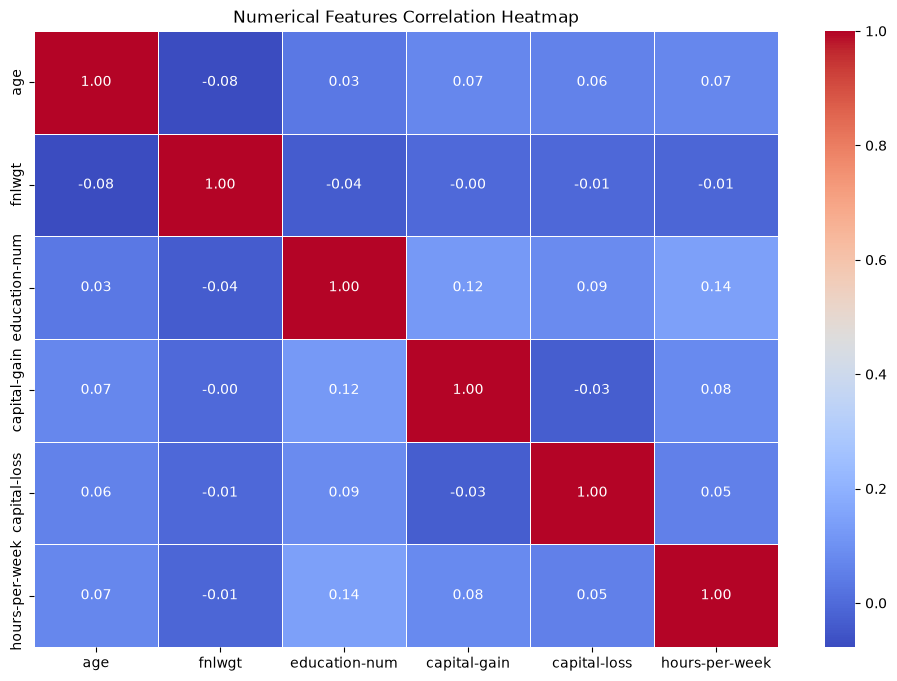

In [60]:
plt.figure(figsize =(12,8))

sns.heatmap(
    correlation_matrix,
    annot = True,
    cmap = "coolwarm",
    fmt =".2f",
    linewidths = 0.5
)

plt.title("Numerical Features Correlation Heatmap")
plt.show()

In [61]:
correlation_pairs = correlation_matrix.unstack()
high_correlations = correlation_pairs[
    (correlation_pairs.abs()>0.70)&
    (correlation_pairs.abs()<1.0)
]
print("Highly correlated Features pairs :")
print(high_correlations)

Highly correlated Features pairs :
Series([], dtype: float64)


In [62]:
from sklearn.feature_selection import mutual_info_classif

# Get transformed feature names
feature_names = preprocessor.get_feature_names_out()

# Identify categorical encoded features
discrete_mask = np.array([
    name.startswith("cat__") for name in feature_names
])

# Calculate mutual information scores
mi_scores = mutual_info_classif(
    X_train_processed,
    Y_train,
    discrete_features=discrete_mask,
    random_state=42
)

# Create feature importance dataframe
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "MI_Score": mi_scores
})

feature_importance = feature_importance.sort_values(
    by="MI_Score",
    ascending=False
)

display(feature_importance.head(15))

NameError: name 'pd' is not defined